# BÀI THỰC HÀNH 2: MẠNG NEURAL TÍCH CHẬP

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses..

Bộ dữ liệu sử dụng: [VinaFood21 dataset](https://arxiv.org/abs/2108.02929).

Link download: https://drive.google.com/file/d/1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR/view?usp=share_link.

Lưu ý: xem hình ảnh trong file docx hướng dẫn bài tập để tránh tình trạng bị nhảy ảnh

In [1]:
import math, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("torch  :", torch.__version__)
print("device :", device)

torch  : 2.12.0+cpu
device : cpu


In [2]:
def n_params(module, trainable_only=False):
    ps = module.parameters()
    if trainable_only:
        ps = (p for p in module.parameters() if p.requires_grad)
    return sum(p.numel() for p in ps)


def show(label, t):
    print(f"{label:<28} {tuple(t.shape)}")

In [3]:
from pathlib import Path

DATA_ROOT = Path("VinaFood21")
IMG_SIZE = 64
BATCH = 32
SEED = 42

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

In [4]:
def make_loaders(img_size, augment=True, val_ratio=0.1):
    eval_tf = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(img_size, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ]) if augment else eval_tf

    if (DATA_ROOT / "val").is_dir():
        tr = datasets.ImageFolder(DATA_ROOT / "train", train_tf)
        va = datasets.ImageFolder(DATA_ROOT / "val", eval_tf)
    else:  # không có val/ thì tách từ train bằng random_split, seed 42
        n = len(datasets.ImageFolder(DATA_ROOT / "train"))
        n_val = int(val_ratio * n)
        tr_idx, va_idx = [list(s.indices) for s in random_split(
            range(n), [n - n_val, n_val], generator=torch.Generator().manual_seed(SEED))]
        tr = Subset(datasets.ImageFolder(DATA_ROOT / "train", train_tf), tr_idx)
        va = Subset(datasets.ImageFolder(DATA_ROOT / "train", eval_tf),  va_idx)

    te = datasets.ImageFolder(DATA_ROOT / "test", eval_tf)
    classes = datasets.ImageFolder(DATA_ROOT / "train").classes

    mk = lambda ds, sh: DataLoader(ds, batch_size=BATCH, shuffle=sh, num_workers=2)
    return mk(tr, True), mk(va, False), mk(te, False), classes

In [5]:
train_dl, val_dl, test_dl, CLASSES = make_loaders(IMG_SIZE, augment=True)

print("số lớp      :", len(CLASSES))
print("số ảnh train:", len(train_dl.dataset), "| val:", len(val_dl.dataset),
      "| test:", len(test_dl.dataset))
print("thứ tự lớp  :", CLASSES[:5], "...")

số lớp      : 21
số ảnh train: 9040 | val: 1004 | test: 6682
thứ tự lớp  : ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron'] ...


In [6]:
anh, nhan = train_dl.dataset[0]
xb, yb = next(iter(train_dl))
show("một ảnh sau transform", anh)
show("một batch vào model", xb)
show("nhãn", yb)

một ảnh sau transform        (3, 64, 64)
một batch vào model          (32, 3, 64, 64)
nhãn                         (32,)


In [7]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total, correct, running = 0, 0, 0.0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item() * yb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += yb.size(0)
    return running / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total, correct, running = 0, 0, 0.0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        running += criterion(logits, yb).item() * yb.size(0)
        pred = logits.argmax(1)
        correct += (pred == yb).sum().item()
        total += yb.size(0)
        y_true += yb.cpu().tolist()
        y_pred += pred.cpu().tolist()
    return running / total, correct / total, y_true, y_pred

def run_experiment(name, model, loaders, epochs=20, lr=1e-3):
    train_dl, val_dl, test_dl, _ = loaders
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)

    history, times, best_val, best_state = [], [], float("inf"), None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_dl, criterion, optimizer, device)
        va_loss, va_acc, _, _ = evaluate(model, val_dl, criterion, device)
        times.append(time.time() - t0)
        history.append((ep, tr_loss, va_loss))
        if va_loss < best_val:
            best_val = va_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep:>2} train {tr_loss:.4f}/{tr_acc:.4f}  val {va_loss:.4f}/{va_acc:.4f}")

    model.load_state_dict(best_state)
    _, _, y_true, y_pred = evaluate(model, test_dl, criterion, device)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return dict(name=name, params=n_params(model), sec_per_epoch=sum(times) / len(times),
                acc=accuracy_score(y_true, y_pred), precision=p, recall=r, f1=f1,
                history=history, y_true=y_true, y_pred=y_pred)

def report(res, classes):
    plt.figure(figsize=(12, 10))
    sns.heatmap(confusion_matrix(res["y_true"], res["y_pred"]),
                xticklabels=classes, yticklabels=classes, cmap="Blues")
    plt.title(res["name"]); plt.show()

def plot_loss(res):
    ep, tr, va = zip(*res["history"])
    plt.plot(ep, tr, label="train"); plt.plot(ep, va, label="val")
    plt.xlabel("epoch"); plt.ylabel("loss"); plt.title(res["name"]); plt.legend(); plt.show()

### Bài 1: Xây dựng mô hình LeNet. Huấn luyện và đánh giá mô hình LeNet trên 4 độ đo precision, recall và F1-macro (sử dụng Adam làm optimizer).

In [8]:
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, img=64, num_classes=21, pool="avg"):
        super().__init__()
        Pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.c1 = nn.Conv2d(in_ch, 6, kernel_size=5)
        self.s2 = Pool(2, 2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = Pool(2, 2)
        n_flat = self._flat_dim(in_ch, img)
        self.f5 = nn.Linear(n_flat, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, num_classes)
        self.n_flat = n_flat

    def _flat_dim(self, in_ch, img):
        with torch.no_grad():
            z = torch.zeros(1, in_ch, img, img)
            z = self.s4(self.c3(self.s2(self.c1(z))))
        return int(z.flatten(1).shape[1])

    def forward(self, x):
        x = self.s2(torch.relu(self.c1(x)))
        x = self.s4(torch.relu(self.c3(x)))
        x = x.flatten(1)
        x = torch.relu(self.f5(x))
        x = torch.relu(self.f6(x))
        return self.out(x)

def layer_table(model, img, in_ch=3):
    x = torch.zeros(1, in_ch, img, img)
    rows, total = [], 0
    for name, layer in [("C1", model.c1), ("S2", model.s2), ("C3", model.c3), ("S4", model.s4)]:
        x = layer(x); p = n_params(layer); total += p
        rows.append((name, "x".join(map(str, tuple(x.shape)[1:])), p))
    x = x.flatten(1)
    rows.append(("flatten", str(x.shape[1]), 0))
    for name, layer in [("F5", model.f5), ("F6", model.f6), ("OUT", model.out)]:
        x = layer(x); p = n_params(layer); total += p
        rows.append((name, str(x.shape[1]), p))
    return rows, total

In [9]:
lenet = LeNet5(in_ch=3, img=64, num_classes=21)
assert lenet.n_flat == 2704 and n_params(lenet) == 339_421

rows, total = layer_table(lenet, 64)
print(f"{'layer':<10}{'output':<16}{'tham số':>12}")
for name, shape, p in rows:
    print(f"{name:<10}{shape:<16}{p:>12,}")
print(f"{'TỔNG':<10}{'':<16}{total:>12,}")

layer     output               tham số
C1        6x60x60                  456
S2        6x30x30                    0
C3        16x26x26               2,416
S4        16x13x13                   0
flatten   2704                       0
F5        120                  324,600
F6        84                    10,164
OUT       21                     1,785
TỔNG                           339,421


In [10]:
loaders64 = make_loaders(64, augment=True)
CLASSES = loaders64[3]

res_avg = run_experiment("LeNet-5 AvgPool", LeNet5(pool="avg"), loaders64)
res_max = run_experiment("LeNet-5 MaxPool", LeNet5(pool="max"), loaders64)

print("macro-F1  Avg:", res_avg["f1"], " Max:", res_max["f1"])

[LeNet-5 AvgPool] epoch  1 train 2.8103/0.1437  val 2.7454/0.1524
[LeNet-5 AvgPool] epoch  2 train 2.6052/0.2055  val 2.4842/0.2331
[LeNet-5 AvgPool] epoch  3 train 2.4668/0.2418  val 2.4366/0.2430
[LeNet-5 AvgPool] epoch  4 train 2.4039/0.2549  val 2.3698/0.2610
[LeNet-5 AvgPool] epoch  5 train 2.3327/0.2767  val 2.3480/0.2789
[LeNet-5 AvgPool] epoch  6 train 2.2562/0.2965  val 2.3375/0.2789
[LeNet-5 AvgPool] epoch  7 train 2.2179/0.3124  val 2.2292/0.3108
[LeNet-5 AvgPool] epoch  8 train 2.1563/0.3315  val 2.2399/0.3068
[LeNet-5 AvgPool] epoch  9 train 2.1001/0.3491  val 2.2163/0.3098
[LeNet-5 AvgPool] epoch 10 train 2.0730/0.3591  val 2.1976/0.3167
[LeNet-5 AvgPool] epoch 11 train 2.0239/0.3713  val 2.1953/0.3227
[LeNet-5 AvgPool] epoch 12 train 1.9895/0.3827  val 2.1204/0.3357
[LeNet-5 AvgPool] epoch 13 train 1.9678/0.3878  val 2.0986/0.3337
[LeNet-5 AvgPool] epoch 14 train 1.9207/0.4017  val 2.1148/0.3496
[LeNet-5 AvgPool] epoch 15 train 1.8994/0.4080  val 2.1541/0.3406
[LeNet-5 A

**Nhận xét:**

- Huấn luyện: Train loss giảm đều (AvgPool 2.81 -> 1.78, MaxPool 2.83 -> 1.83). Từ khoảng epoch 6, val loss cao hơn train loss và khoảng cách rộng dần (epoch 20: AvgPool 2.09 so với 1.78, MaxPool 2.16 so với 1.83), nhưng val accuracy vẫn còn tăng nên overfitting chưa rõ. Train accuracy chỉ khoảng 0.43–0.44, cho thấy mô hình chủ yếu đang underfitting, có thể do LeNet nhỏ và ảnh 64×64.
- AvgPool so với MaxPool: Hai bản khá sát nhau: val loss thấp nhất 2.056 (Avg) so với 2.053 (Max); val accuracy cao nhất 0.372 so với 0.379. Macro-F1 test: AvgPool = 0.2881, MaxPool = 0.3036, MaxPool nhỉnh hơn khoảng 1.5 điểm. Có thể do MaxPool giữ lại giá trị kích hoạt lớn nhất trong mỗi cửa sổ 2x2 (nơi đặc trưng nổi rõ nhất), còn AvgPool lấy trung bình nên đặc trưng bị loãng đi.

=> Kết luận: Cùng 339,421 tham số, MaxPool cho macro-F1 cao hơn AvgPool một chút.

,Mô hình,Tham số,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,LeNet-5 AvgPool,"339,421",0.3116,0.3013,0.2903,0.2881
1,LeNet-5 MaxPool,"339,421",0.3260,0.3350,0.3069,0.3036


,lớp,F1 AvgPool,F1 MaxPool
0,banh-can,0.1827,0.1750
1,banh-hoi,0.3951,0.3651
2,banh-mi-chao,0.2966,0.2609
3,banh-tet,0.3158,0.3289
4,banh-trang-tron,0.1842,0.2258
5,banh-u,0.1329,0.1688
6,banh-uot,0.3158,0.3213
7,bap-nuong,0.1391,0.0629
8,bo-kho,0.3455,0.3555
9,bo-la-lot,0.4809,0.4633


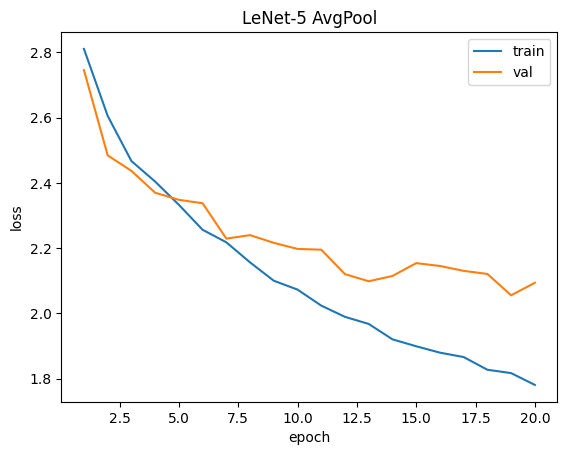

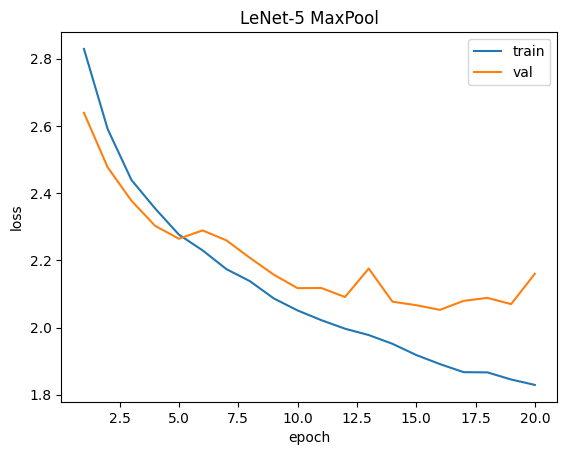

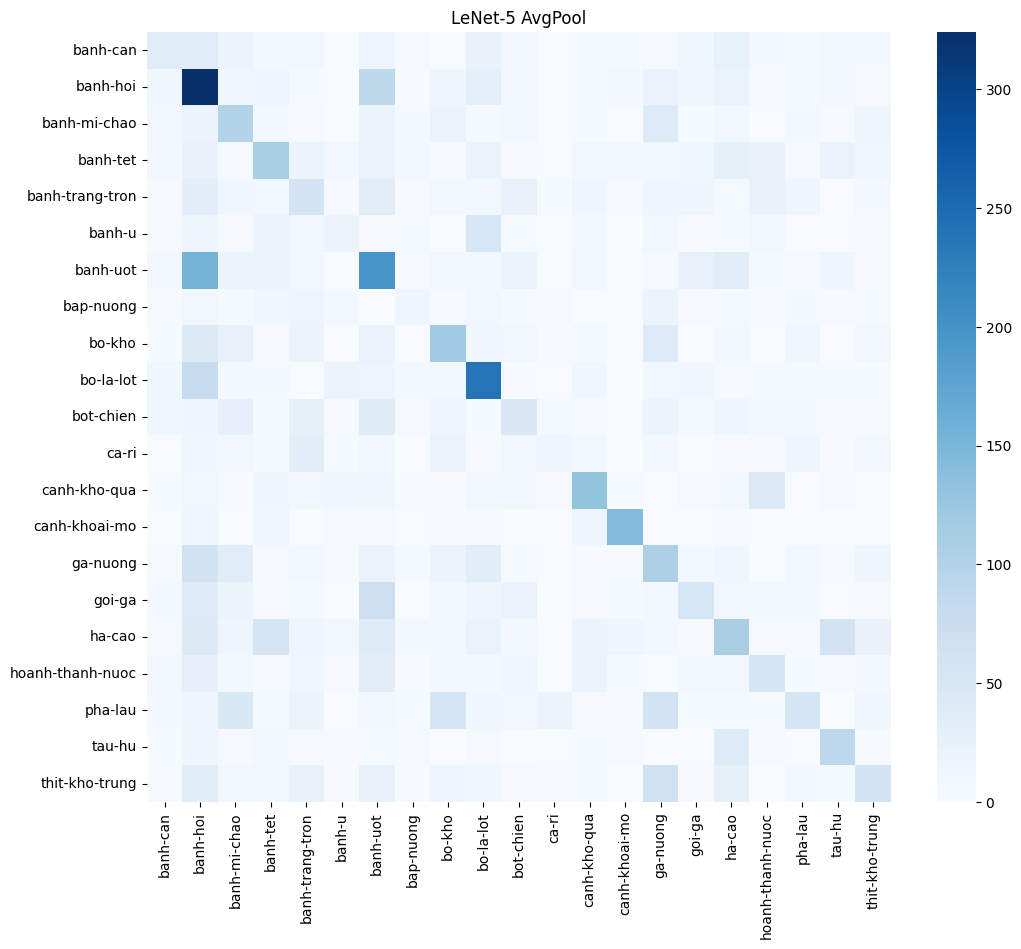

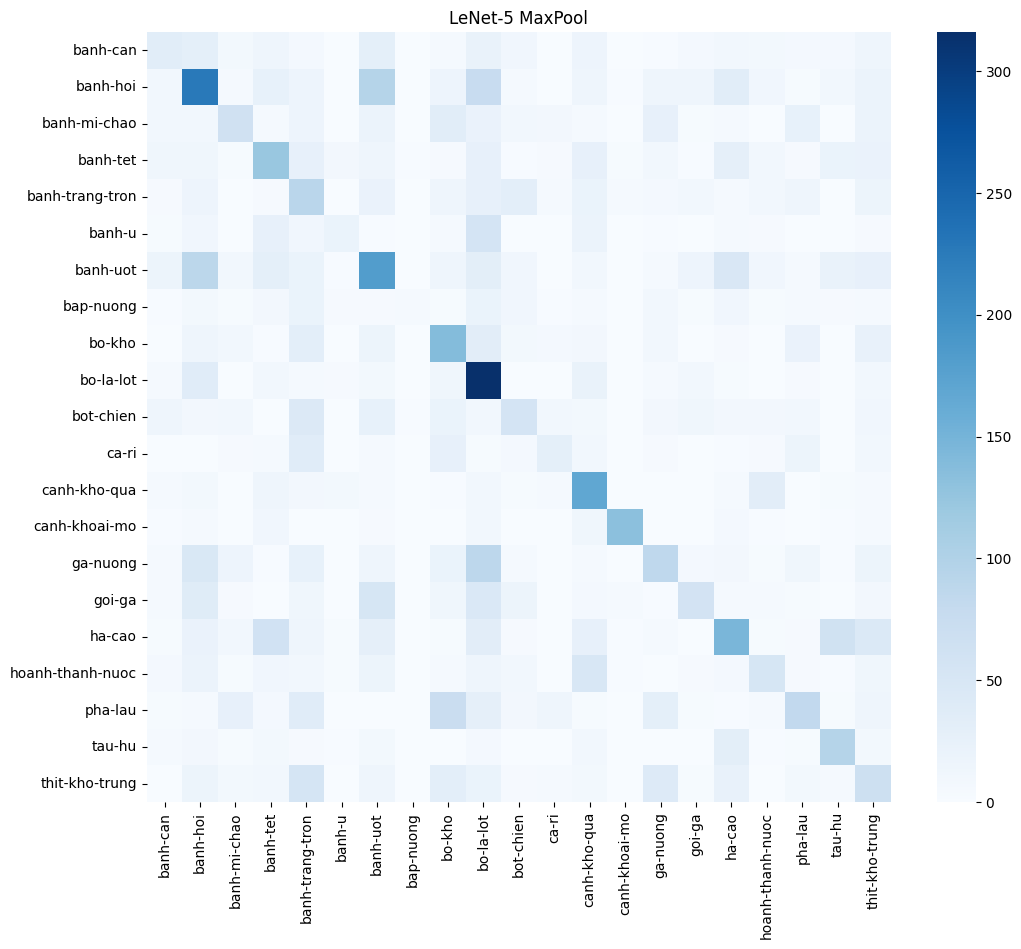

In [11]:
df_metrics = pd.DataFrame([{
    "Mô hình": r["name"], "Tham số": f"{r['params']:,}",
    "Accuracy": round(r["acc"], 4), "Precision (macro)": round(r["precision"], 4),
    "Recall (macro)": round(r["recall"], 4), "F1 (macro)": round(r["f1"], 4),
} for r in (res_avg, res_max)])
display(df_metrics)

def f1_per_class(res):
    return precision_recall_fscore_support(
        res["y_true"], res["y_pred"], average=None, zero_division=0)[2].round(4)

display(pd.DataFrame({"lớp": CLASSES,
                      "F1 AvgPool": f1_per_class(res_avg),
                      "F1 MaxPool": f1_per_class(res_max)}))

plot_loss(res_avg)
plot_loss(res_max)
report(res_avg, CLASSES)
report(res_max, CLASSES)

**Nhận xét:**

- Train loss giảm đều, val loss cao hơn train từ khoảng epoch 6 nhưng val accuracy vẫn tăng, nên overfitting chưa rõ. Accuracy còn thấp, có thể do LeNet nhỏ và ảnh chỉ 64x64.
- MaxPool nhỉnh hơn AvgPool ở cả 4 độ đo (cùng 339,421 tham số): macro-F1 0.3036 so với 0.2881, accuracy 0.3260 so với 0.3116, precision 0.3350 so với 0.3013, recall 0.3069 so với 0.2903. MaxPool cao hơn ở 14/21 lớp.
- Confusion matrix: AvgPool có nhiều lớp bị dự đoán nhầm sang banh-hoi. Cả hai bản hay nhầm banh-hoi với banh-uot và ha-cao với tau-hu. Lớp kém nhất là bap-nuong (F1 0.14 với AvgPool, 0.06 với MaxPool) và banh-u, ngoài ra ca-ri rất thấp với AvgPool (0.12) còn banh-can thấp với MaxPool (0.18).

**Vì sao MaxPool tốt hơn?**

Sau ReLU feature map có nhiều giá trị 0 và chỉ vài vị trí kích hoạt mạnh. MaxPool giữ giá trị kích hoạt lớn nhất trong cửa sổ 2x2, còn AvgPool lấy trung bình nên các kích hoạt mạnh bị pha loãng. MaxPool cũng ít nhạy với vị trí chính xác của đặc trưng.

=> Kết luận: MaxPool nhỉnh hơn AvgPool trong cùng cấu hình, nhưng LeNet vẫn còn yếu trên VinaFood21 (macro-F1 khoảng 0.29-0.30), cần mô hình sâu hơn hoặc transfer learning.

### Bài 2: Xây dựng mô hình GoogLeNet. Huấn luyện và đánh giá mô hình GoogLeNet trên 4 độ đo precision, recall và F1 (sử dụng Adam làm optimizer).

**Inception Blocks**


**GoogLeNet (Multi-branch Network)**

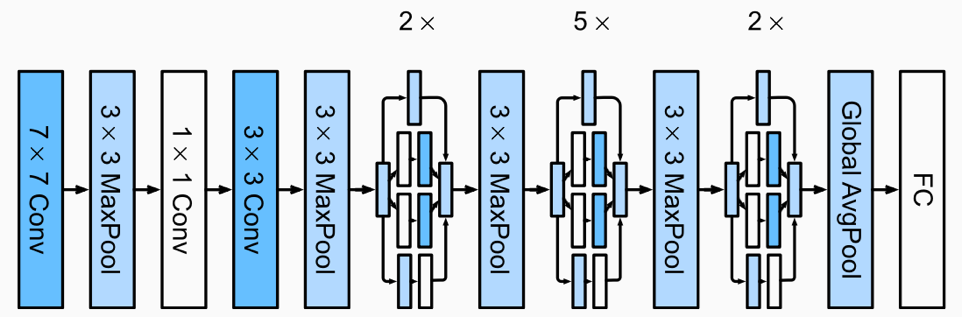
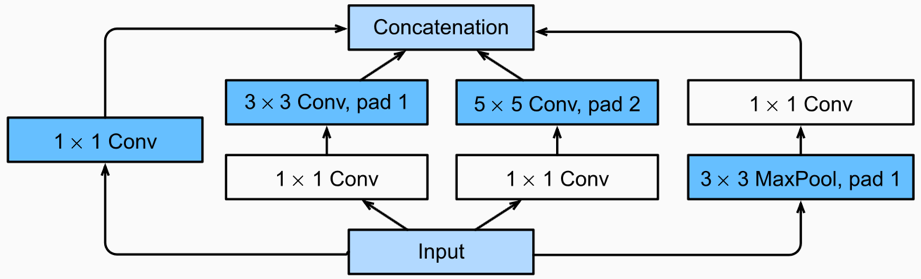

In [27]:
class InceptionBlock(nn.Module):
    def __init__(self, in_ch, f1, f3r, f3, f5r, f5, fp):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(in_ch, f1, 1), nn.ReLU())
        self.b2 = nn.Sequential(nn.Conv2d(in_ch, f3r, 1), nn.ReLU(),
                                nn.Conv2d(f3r, f3, 3, padding=1), nn.ReLU())
        self.b3 = nn.Sequential(nn.Conv2d(in_ch, f5r, 1), nn.ReLU(),
                                nn.Conv2d(f5r, f5, 5, padding=2), nn.ReLU())
        self.b4 = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1),
                                nn.Conv2d(in_ch, fp, 1), nn.ReLU())

    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

# Đối chiếu với hai block mẫu trong đề
blk_a = InceptionBlock(1, 16, 16, 24, 4, 8, 8)
blk_b = InceptionBlock(56, 32, 32, 48, 8, 16, 16)
assert blk_a(torch.rand(1, 1, 28, 28)).shape[1] == 56 and n_params(blk_a) == 4_376
assert blk_b(torch.rand(1, 56, 14, 14)).shape[1] == 112 and n_params(blk_b) == 22_104
print("Block 1: 56 channel, 4,376 tham số | Block 2: 112 channel, 22,104 tham số")

class GoogLeNetMini(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2, 2))  # 64->32
        self.inc1 = InceptionBlock(32, 16, 16, 24, 4, 8, 8)      # 56
        self.inc2 = InceptionBlock(56, 32, 32, 48, 8, 16, 16)    # 112
        self.pool = nn.MaxPool2d(2, 2)                           # 32->16
        self.inc3 = InceptionBlock(112, 48, 48, 64, 8, 16, 16)   # 144
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(144, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.inc2(self.inc1(x))
        x = self.inc3(self.pool(x))
        return self.fc(self.gap(x).flatten(1))

Block 1: 56 channel, 4,376 tham số | Block 2: 112 channel, 22,104 tham số


In [28]:
g = GoogLeNetMini()
cfg = {"inc1": (16, 24, 8, 8), "inc2": (32, 48, 16, 16), "inc3": (48, 64, 16, 16)}  # (f1, f3, f5, fp)

x = g.stem(torch.zeros(1, 3, 64, 64))
print(f"{'stem':<8}{str(tuple(x.shape)):<22}{n_params(g.stem):>8,} tham số")
print(f"{'block':<8}{'output shape':<22}{'channel tính tay':<20}{'tham số':>8}")

for name in ("inc1", "inc2", "inc3"):
    if name == "inc3":
        x = g.pool(x)
    x = getattr(g, name)(x)
    hand = sum(cfg[name])  # f1 + f3 + f5 + fp
    print(f"{name:<8}{str(tuple(x.shape)):<22}{hand:<20}{n_params(getattr(g, name)):>8,}")
    assert x.shape[1] == hand

v = g.gap(x).flatten(1)
print(f"{'gap':<8}{str(tuple(v.shape)):<22}")
print(f"{'fc':<8}{str(tuple(g.fc(v).shape)):<22}{n_params(g.fc):>8,} tham số")
print("TỔNG:", f"{n_params(g):,}")
assert n_params(g) == 76_273

stem    (1, 32, 32, 32)            896 tham số
block   output shape          channel tính tay     tham số
inc1    (1, 56, 32, 32)       56                     5,740
inc2    (1, 112, 32, 32)      112                   22,104
inc3    (1, 144, 16, 16)      144                   44,488
gap     (1, 144)              
fc      (1, 21)                  3,045 tham số
TỔNG: 76,273


In [29]:
res_goog = run_experiment("GoogLeNet mini", GoogLeNetMini(), loaders64)
print("macro-F1:", res_goog["f1"])

df2 = pd.DataFrame([{
    "Mô hình": r["name"], "Tham số": f"{r['params']:,}",
    "Giây/epoch": round(r["sec_per_epoch"], 1),
    "Accuracy": round(r["acc"], 4), "Precision (macro)": round(r["precision"], 4),
    "Recall (macro)": round(r["recall"], 4), "F1 (macro)": round(r["f1"], 4),
} for r in (res_avg, res_max, res_goog)])
display(df2)

[GoogLeNet mini] epoch  1 train 2.8975/0.1173  val 2.7831/0.1434
[GoogLeNet mini] epoch  2 train 2.6577/0.1845  val 2.6007/0.1972
[GoogLeNet mini] epoch  3 train 2.4857/0.2275  val 2.4957/0.2321
[GoogLeNet mini] epoch  4 train 2.3879/0.2615  val 2.4242/0.2430
[GoogLeNet mini] epoch  5 train 2.3175/0.2824  val 2.3519/0.2719
[GoogLeNet mini] epoch  6 train 2.2493/0.3015  val 2.2599/0.3197
[GoogLeNet mini] epoch  7 train 2.2085/0.3150  val 2.2572/0.3217
[GoogLeNet mini] epoch  8 train 2.1498/0.3365  val 2.2203/0.3317
[GoogLeNet mini] epoch  9 train 2.1080/0.3416  val 2.1787/0.3436
[GoogLeNet mini] epoch 10 train 2.0734/0.3619  val 2.1126/0.3635
[GoogLeNet mini] epoch 11 train 2.0311/0.3739  val 2.0646/0.3596
[GoogLeNet mini] epoch 12 train 1.9907/0.3832  val 2.1835/0.3396
[GoogLeNet mini] epoch 13 train 1.9575/0.3965  val 2.0072/0.3725
[GoogLeNet mini] epoch 14 train 1.9351/0.4017  val 1.9350/0.4114
[GoogLeNet mini] epoch 15 train 1.8958/0.4152  val 1.9370/0.3954
[GoogLeNet mini] epoch 16

,Mô hình,Tham số,Giây/epoch,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,LeNet-5 AvgPool,"339,421",109.6,0.3116,0.3013,0.2903,0.2881
1,LeNet-5 MaxPool,"339,421",97.1,0.3260,0.3350,0.3069,0.3036
2,GoogLeNet mini,"76,273",176.2,0.3942,0.4033,0.3771,0.3708


**Nhận xét:**
- Train loss giảm đều (2.90 -> 1.77), val loss bám sát train, gần như không overfitting. Val loss thấp nhất 1.858 ở epoch 19.
- Test: accuracy 0.3942, macro-F1 0.3708.
- So với LeNet: GoogLeNet mini có macro-F1 cao hơn (0.3708 so với 0.2881 và 0.3036) dù chỉ có 76,273 tham số (ít hơn khoảng 4.5 lần), nhưng chậm hơn (176.2 giây/epoch so với 109.6 và 97.1).
- Có thể do dùng `AdaptiveAvgPool2d(1)` thay `Flatten` nên không có lớp fully connected lớn, và các nhánh Inception nhìn ảnh ở nhiều cỡ cùng lúc.

,lớp,F1 LeNet (Avg),F1 LeNet (Max),F1 GoogLeNet
0,banh-can,0.1827,0.1750,0.2284
1,banh-hoi,0.3951,0.3651,0.4544
2,banh-mi-chao,0.2966,0.2609,0.4184
3,banh-tet,0.3158,0.3289,0.4583
4,banh-trang-tron,0.1842,0.2258,0.2615
5,banh-u,0.1329,0.1688,0.3062
6,banh-uot,0.3158,0.3213,0.4076
7,bap-nuong,0.1391,0.0629,0.2273
8,bo-kho,0.3455,0.3555,0.4000
9,bo-la-lot,0.4809,0.4633,0.6285


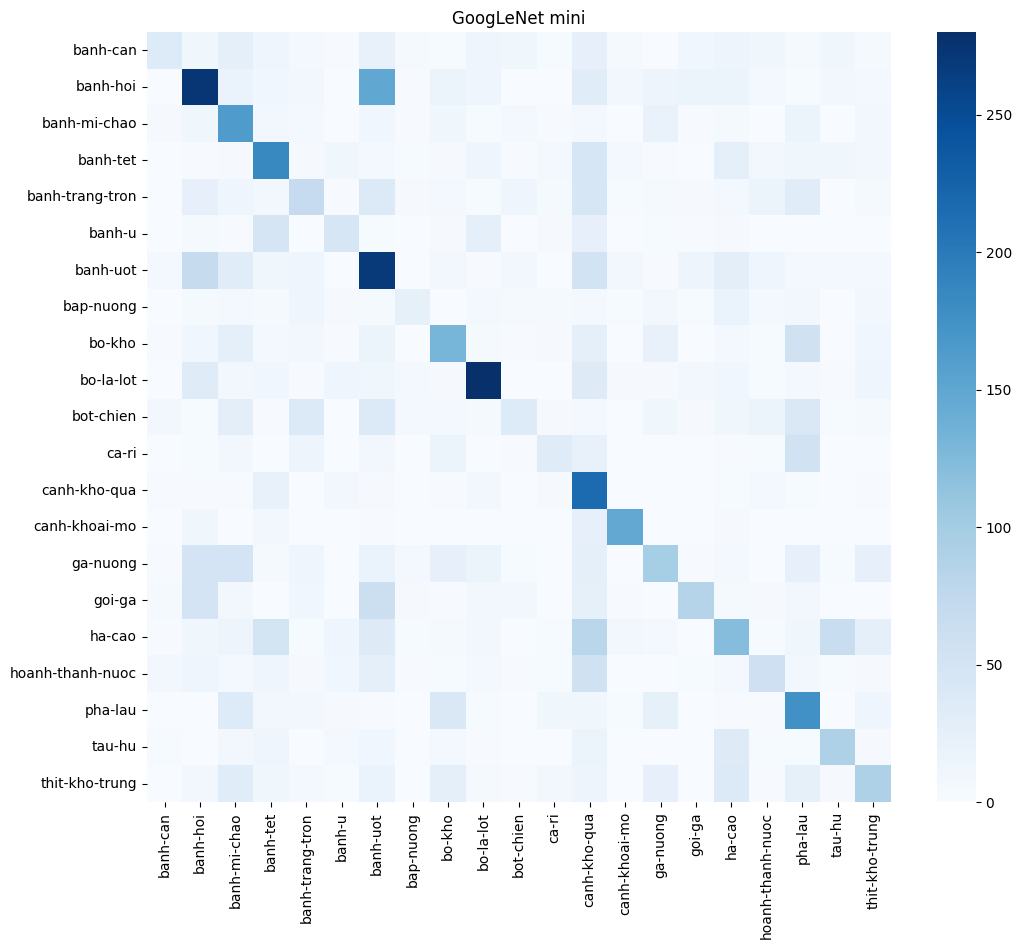

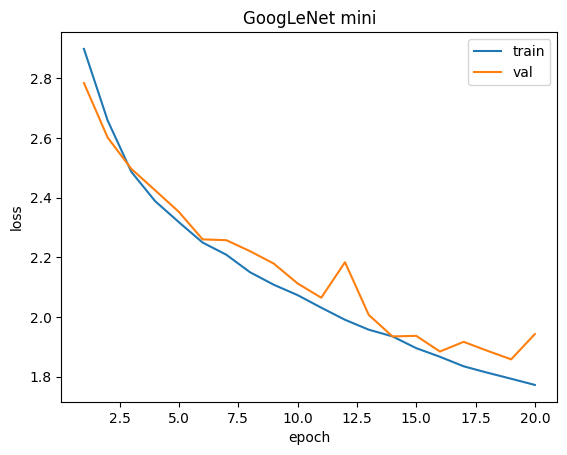

In [30]:
display(pd.DataFrame({"lớp": CLASSES,
                      "F1 LeNet (Avg)": f1_per_class(res_avg),
                      "F1 LeNet (Max)": f1_per_class(res_max),
                      "F1 GoogLeNet": f1_per_class(res_goog)}))

report(res_goog, CLASSES)
plot_loss(res_goog)

**Nhận xét:**

Đường loss (GoogLeNet mini):
- Train loss và val loss giảm cùng nhau, bám sát nhau suốt 20 epoch, gần như không overfitting.
- Val loss có một lần nhảy lên ở epoch 12 (2.18), thấp nhất 1.858 ở epoch 19, rồi tăng nhẹ ở epoch 20. Hai đường vẫn đang đi xuống nên mô hình có thể còn cải thiện nếu chạy thêm.

F1 từng lớp:
- GoogLeNet cao hơn LeNet AvgPool ở 20/21 lớp và cao hơn LeNet MaxPool ở 17/21 lớp.
- Tăng mạnh nhất so với AvgPool: pha-lau (0.21 -> 0.41), banh-u (0.13 -> 0.31), goi-ga (0.22 -> 0.38), bo-la-lot (0.48 -> 0.63), banh-tet (0.32 -> 0.46).
- Giảm: canh-kho-qua (0.46 -> 0.40, thấp hơn cả hai bản LeNet). So với MaxPool còn kém hơn ở bot-chien, canh-khoai-mo và ha-cao (chênh nhỏ).
- Dễ nhận diện nhất: canh-khoai-mo (0.73) và bo-la-lot (0.63). Khó nhất: bot-chien (0.19), bap-nuong, banh-can, ca-ri (khoảng 0.23-0.24).

Confusion matrix:
- Đường chéo rõ hơn LeNet ở nhiều lớp (banh-hoi, banh-uot, bo-la-lot, canh-kho-qua, pha-lau).
- Cột canh-kho-qua có nhiều ô nhạt: một số lớp (banh-tet, ha-cao, banh-trang-tron, hoanh-thanh-nuoc) bị đoán nhầm thành canh-kho-qua, có thể là nguyên nhân F1 của lớp này giảm.
- Vẫn nhầm banh-hoi với banh-uot như ở Bài 1.

### Bài 3*: Xây dựng mô hình ResNet-18, đánh giá mô hình ResNet-18 trên bộ dữ liệu VinaFood21 sử dụng các độ đo precision, recall, và F1 (Sử dụng Adam làm optimizer).

**ResNet Block**


**ResNet**

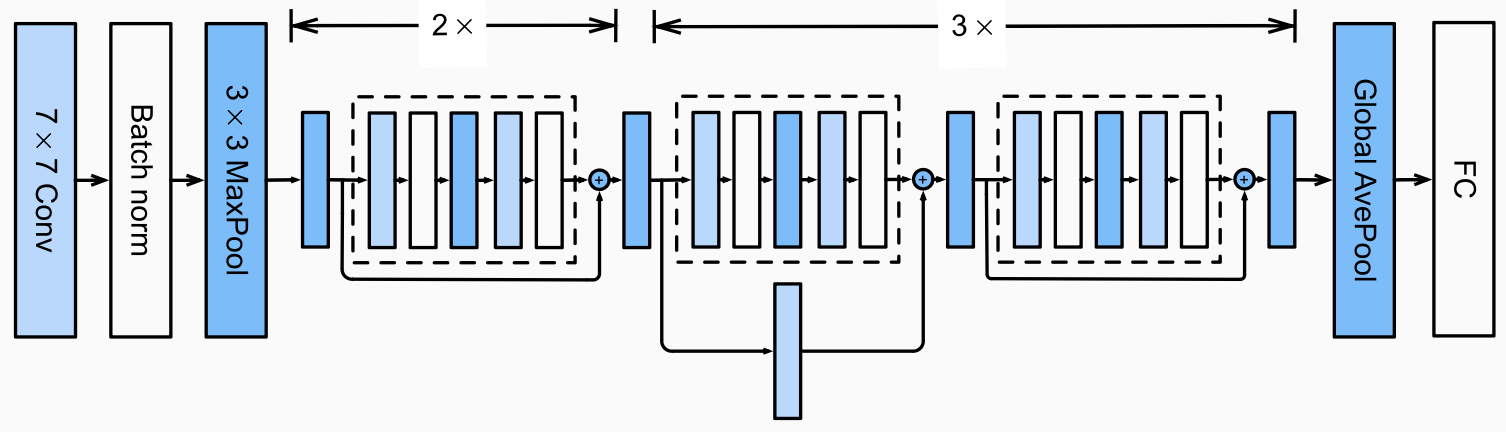
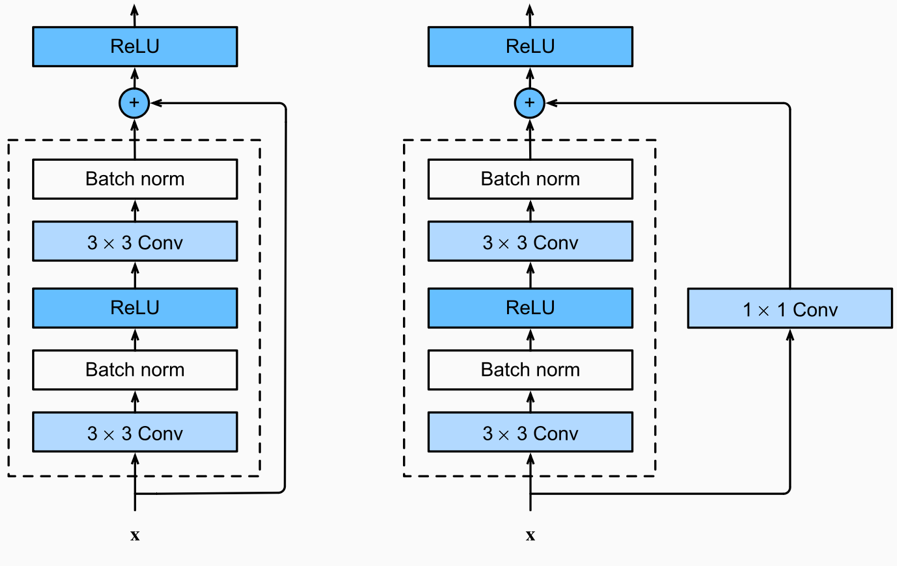

In [15]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch: # Đổi shape thì cần projection
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + self.shortcut(x) # Cộng trước
        return torch.relu(out)       # ReLU sau


class ResNet18(nn.Module):
    def __init__(self, num_classes=21):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1))
        self.layer1 = self._stage(64, 64, stride=1)
        self.layer2 = self._stage(64, 128, stride=2)
        self.layer3 = self._stage(128, 256, stride=2)
        self.layer4 = self._stage(256, 512, stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(512, num_classes)

    @staticmethod
    def _stage(in_ch, out_ch, stride):
        # Block đầu đổi channel và giảm chiều, block sau giữ nguyên
        return nn.Sequential(BasicBlock(in_ch, out_ch, stride),
                             BasicBlock(out_ch, out_ch, 1))

    def forward(self, x):
        x = self.stem(x)
        for layer in (self.layer1, self.layer2, self.layer3, self.layer4):
            x = layer(x)
        return self.fc(self.pool(x).flatten(1))

In [16]:
r18 = ResNet18(num_classes=21)
assert n_params(r18) == 11_187_285
print("tổng tham số:", f"{n_params(r18):,}")

# Bảng shape và tham số qua từng stage, ảnh vào 96x96
x = torch.rand(1, 3, 96, 96)
print(f"{'stage':<10}{'output shape':<20}{'tham số':>12}")
x = r18.stem(x)
print(f"{'stem':<10}{str(tuple(x.shape)):<20}{n_params(r18.stem):>12,}")
for name in ("layer1", "layer2", "layer3", "layer4"):
    layer = getattr(r18, name)
    x = layer(x)
    print(f"{name:<10}{str(tuple(x.shape)):<20}{n_params(layer):>12,}")
v = r18.pool(x).flatten(1)
print(f"{'fc':<10}{str(tuple(r18.fc(v).shape)):<20}{n_params(r18.fc):>12,}")
assert tuple(x.shape) == (1, 512, 3, 3) # layer4 với 96x96

# Đối chiếu với torchvision
from torchvision.models import resnet18 as tv_resnet18
tv = tv_resnet18(weights=None)
tv.fc = nn.Linear(512, 21)
assert n_params(tv) == n_params(r18) == 11_187_285
print("Khớp với torchvision resnet18.")

tổng tham số: 11,187,285
stage     output shape             tham số
stem      (1, 64, 24, 24)            9,536
layer1    (1, 64, 24, 24)          147,968
layer2    (1, 128, 12, 12)         525,568
layer3    (1, 256, 6, 6)         2,099,712
layer4    (1, 512, 3, 3)         8,393,728
fc        (1, 21)                   10,773
Khớp với torchvision resnet18.


In [17]:
l96_aug = make_loaders(96, augment=True)
l96_noaug = make_loaders(96, augment=False)

In [18]:
res_r18_aug = run_experiment("ResNet-18 có augment", ResNet18(21), l96_aug)

[ResNet-18 có augment] epoch  1 train 2.7004/0.1842  val 2.5061/0.2161
[ResNet-18 có augment] epoch  2 train 2.4609/0.2535  val 2.5405/0.2131
[ResNet-18 có augment] epoch  3 train 2.3120/0.2916  val 2.2161/0.3197
[ResNet-18 có augment] epoch  4 train 2.1868/0.3292  val 2.1973/0.3526
[ResNet-18 có augment] epoch  5 train 2.0843/0.3544  val 2.0800/0.3446
[ResNet-18 có augment] epoch  6 train 1.9734/0.3865  val 1.9150/0.4014
[ResNet-18 có augment] epoch  7 train 1.8545/0.4212  val 1.9752/0.3855
[ResNet-18 có augment] epoch  8 train 1.7811/0.4442  val 1.8527/0.4363
[ResNet-18 có augment] epoch  9 train 1.6948/0.4659  val 1.7792/0.4412
[ResNet-18 có augment] epoch 10 train 1.6262/0.4933  val 1.8964/0.3984
[ResNet-18 có augment] epoch 11 train 1.5505/0.5118  val 1.7362/0.4522
[ResNet-18 có augment] epoch 12 train 1.4857/0.5229  val 1.8788/0.4552
[ResNet-18 có augment] epoch 13 train 1.4133/0.5510  val 1.7264/0.4731
[ResNet-18 có augment] epoch 14 train 1.3416/0.5710  val 1.7338/0.4691
[ResNe

In [19]:
res_r18_noaug = run_experiment("ResNet-18 không augment", ResNet18(21), l96_noaug)

[ResNet-18 không augment] epoch  1 train 2.6252/0.2072  val 2.6498/0.2161
[ResNet-18 không augment] epoch  2 train 2.3478/0.2798  val 2.6498/0.2470
[ResNet-18 không augment] epoch  3 train 2.1580/0.3289  val 2.1025/0.3606
[ResNet-18 không augment] epoch  4 train 2.0001/0.3753  val 2.2241/0.3456
[ResNet-18 không augment] epoch  5 train 1.8287/0.4246  val 1.9986/0.3934
[ResNet-18 không augment] epoch  6 train 1.6352/0.4897  val 1.8464/0.4492
[ResNet-18 không augment] epoch  7 train 1.4302/0.5437  val 1.7925/0.4512
[ResNet-18 không augment] epoch  8 train 1.1718/0.6222  val 1.9993/0.4233
[ResNet-18 không augment] epoch  9 train 0.8917/0.7152  val 1.8615/0.4741
[ResNet-18 không augment] epoch 10 train 0.5661/0.8153  val 2.3538/0.4472
[ResNet-18 không augment] epoch 11 train 0.3912/0.8751  val 2.3774/0.4512
[ResNet-18 không augment] epoch 12 train 0.2515/0.9164  val 2.4783/0.4781
[ResNet-18 không augment] epoch 13 train 0.1574/0.9479  val 2.4751/0.4871
[ResNet-18 không augment] epoch 14 tra

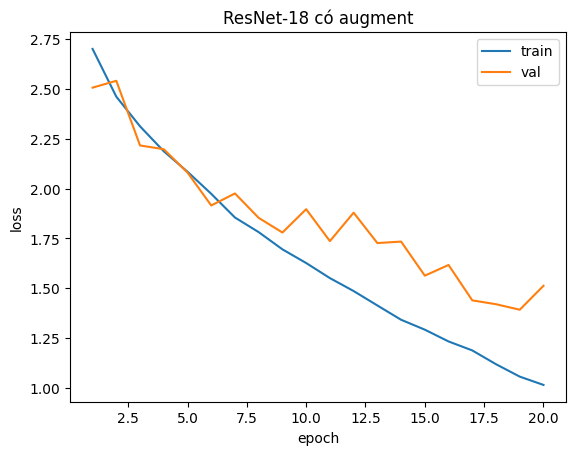

ResNet-18 có augment: hai đường tách nhau từ epoch 10, val loss thấp nhất ở epoch 19


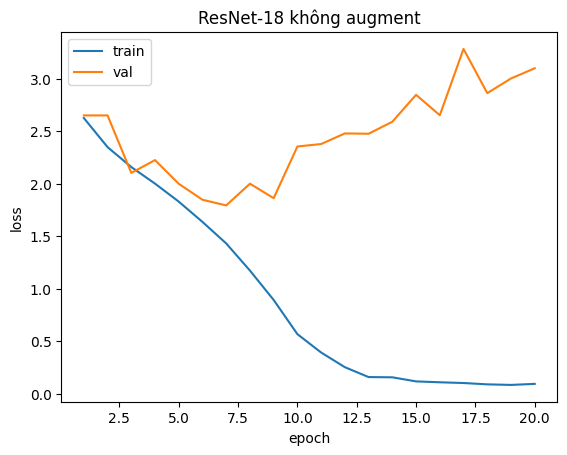

ResNet-18 không augment: hai đường tách nhau từ epoch 2, val loss thấp nhất ở epoch 7


In [20]:
def diverge_epoch(res, gap=0.15):

    for ep, tr, va in res["history"]:
        if va - tr > gap:
            return ep
    return None

def best_epoch(res):
    return min(res["history"], key=lambda h: h[2])[0]

for r in (res_r18_aug, res_r18_noaug):
    plot_loss(r)
    print(f"{r['name']}: hai đường tách nhau từ epoch {diverge_epoch(r)}, "
          f"val loss thấp nhất ở epoch {best_epoch(r)}")

**Nhận xét:**

- Có augmentation: Train loss giảm đều (2.70 -> 1.01), val loss thấp nhất 1.392 ở epoch 19, val accuracy tốt nhất khoảng 0.56. Hai đường tách nhau từ epoch 10 và khoảng cách rộng dần (0.5 ở epoch 20): overfitting vừa phải và đến muộn.
- Không augmentation: Train loss giảm rất nhanh (2.63 -> 0.09, train accuracy 0.97) trong khi val loss thấp nhất chỉ 1.79 ở epoch 7 rồi tăng lên 3.10 ở epoch 20. Theo `diverge_epoch` hai đường tách nhau từ epoch 2 (val loss dao động ở epoch đầu); từ epoch 4 khoảng cách luôn lớn hơn 0.15 và tăng vọt từ epoch 8. Val accuracy chỉ khoảng 0.46-0.49, thấp hơn lần có augmentation.
- So sánh hai lần chạy: Augmentation làm val loss thấp hơn rõ (1.39 so với 1.79), val accuracy cao hơn (0.56 so với 0.49), và dời điểm overfitting muộn hơn (val loss thấp nhất ở epoch 19 so với epoch 7).
- Giải thích: ResNet-18 có 11,187,285 tham số trên khoảng 9 nghìn ảnh train nên dễ học thuộc tập train, nhất là khi không augmentation (train accuracy 0.97, val chỉ khoảng 0.46-0.49). Augmentation (cắt, lật, xoay, đổi màu) làm mỗi epoch thấy ảnh hơi khác nhau nên mô hình khó học thuộc. Kết quả thấp hơn kỳ vọng không có nghĩa là cài sai mà do thiếu dữ liệu so với kích thước mô hình.

,Mô hình,Resize,Tham số,Giây/epoch,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,LeNet-5 AvgPool,64x64,"339,421",109.6,0.3116,0.3013,0.2903,0.2881
1,GoogLeNet mini,64x64,"76,273",163.1,0.3839,0.3900,0.3654,0.3559
2,ResNet-18 có augment,96x96,"11,187,285",242.2,0.5111,0.5216,0.4992,0.4980
3,ResNet-18 không augment,96x96,"11,187,285",259.3,0.3927,0.4087,0.3914,0.3783


chênh macro-F1 (có aug - không aug): 0.1198


,lớp,F1 có aug,F1 không aug
0,banh-can,0.4493,0.2013
1,banh-hoi,0.5733,0.4655
2,banh-mi-chao,0.5627,0.4862
3,banh-tet,0.5761,0.4160
4,banh-trang-tron,0.3386,0.3277
5,banh-u,0.4598,0.2291
6,banh-uot,0.4139,0.3635
7,bap-nuong,0.3862,0.1311
8,bo-kho,0.5652,0.4000
9,bo-la-lot,0.6438,0.5775


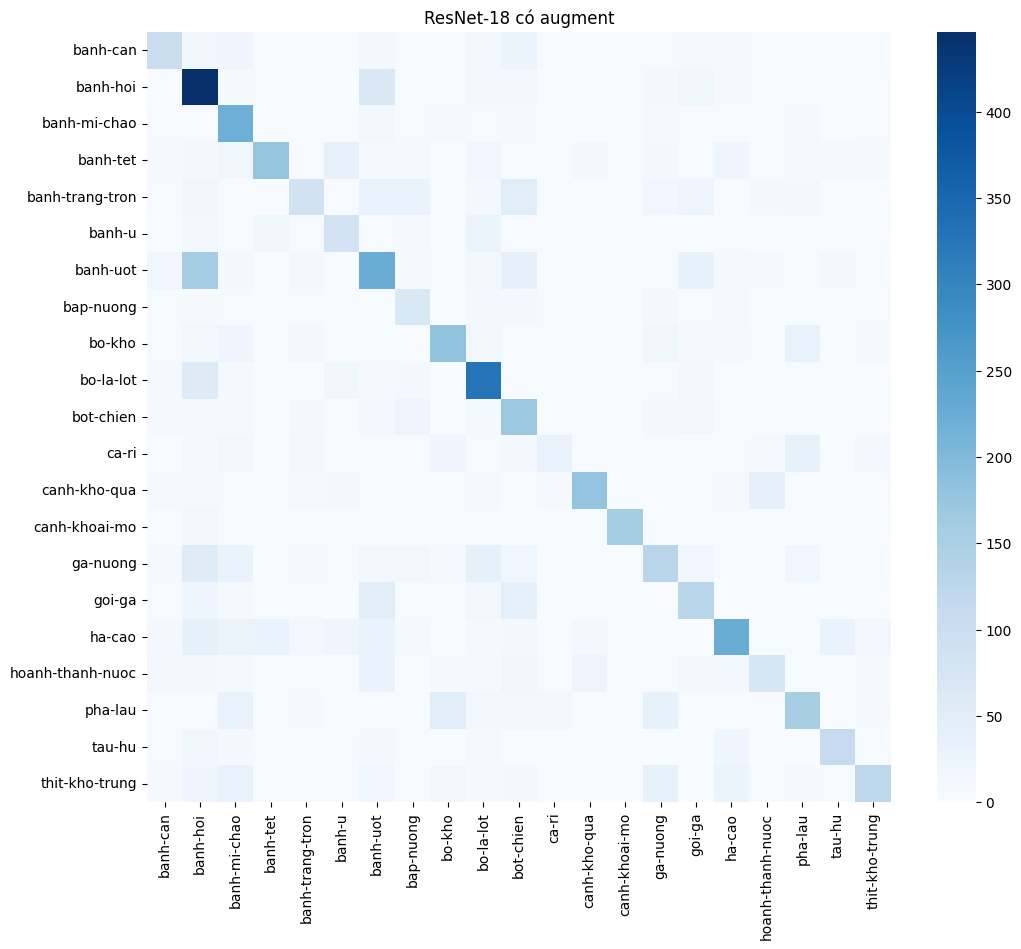

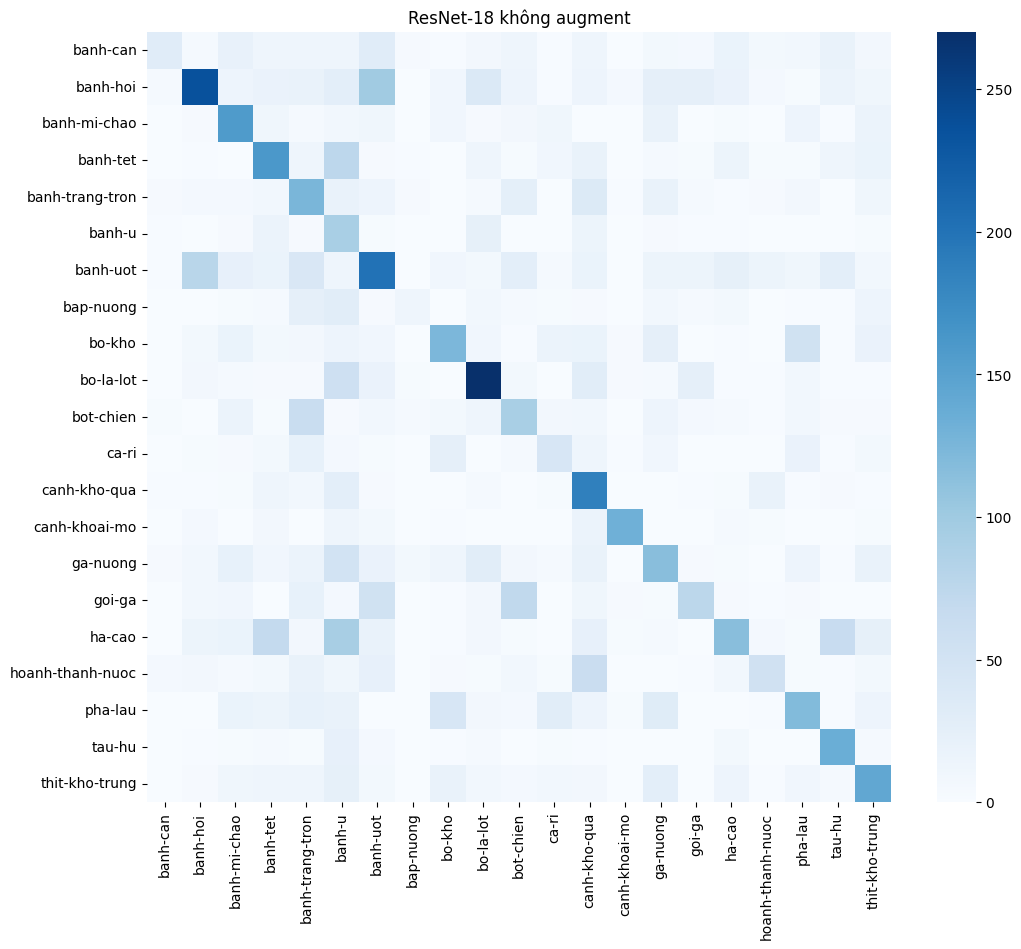

In [21]:
df3 = pd.DataFrame([{
    "Mô hình": r["name"], "Resize": s, "Tham số": f"{r['params']:,}",
    "Giây/epoch": round(r["sec_per_epoch"], 1),
    "Accuracy": round(r["acc"], 4), "Precision (macro)": round(r["precision"], 4),
    "Recall (macro)": round(r["recall"], 4), "F1 (macro)": round(r["f1"], 4),
} for r, s in [(res_avg, "64x64"), (res_goog, "64x64"),
               (res_r18_aug, "96x96"), (res_r18_noaug, "96x96")]])
display(df3)

print("chênh macro-F1 (có aug - không aug):",
      round(res_r18_aug["f1"] - res_r18_noaug["f1"], 4))

display(pd.DataFrame({"lớp": CLASSES,
                      "F1 có aug": f1_per_class(res_r18_aug),
                      "F1 không aug": f1_per_class(res_r18_noaug)}))

report(res_r18_aug, CLASSES)
report(res_r18_noaug, CLASSES)

**Nhận xét:**

Bảng 4 độ đo
- Macro-F1: có augment 0.4980, không augment 0.3783 (chênh 0.1198); accuracy 0.5111 so với 0.3927.
- Cùng 11,187,285 tham số, thời gian mỗi epoch gần như nhau.
- Vượt GoogLeNet mini (0.3559) và LeNet (0.2881), đổi lại nhiều tham số và chậm hơn.
- Lưu ý: GoogLeNet mini ở Bài 2 cho macro-F1 0.3708, lệch với 0.3559 trong bảng này do tính ngẫu nhiên giữa các lần huấn luyện (khởi tạo trọng số, augmentation). ResNet-18 vẫn vượt cả hai số này.

F1 từng lớp
- Có augment cao hơn ở 20/21 lớp (trừ ca-ri); tăng mạnh nhất ở bap-nuong (0.13 -> 0.39) và banh-can, banh-u, ha-cao.
- Dễ nhất: canh-khoai-mo; khó nhất: ca-ri (có augment), bap-nuong (không augment).

Confusion matrix
- Bản có augment có đường chéo rõ hơn; bản không augment phân tán hơn, nhiều ảnh bị đoán nhầm sang banh-u.
- Cả hai vẫn nhầm banh-hoi với banh-uot.

Kết luận
- ResNet-18 có 11 triệu tham số trên khoảng 9 nghìn ảnh nên dễ học thuộc tập train. Augmentation giảm overfitting rõ nhưng chưa đủ.
- Kết quả thấp hơn kỳ vọng không phải do cài sai mà do thiếu dữ liệu so với kích thước mô hình, nên cần transfer learning (Bài 4).

### Bài 4*: Sử dụng pretrained ResNet50 từ HuggingFace để fine-tune trên bộ dữ liệu VinaFood21.

In [9]:
from transformers import ResNetForImageClassification

class PretrainedResnet(nn.Module):
    def __init__(self, num_classes=21, freeze_backbone=False):
        super().__init__()
        base = ResNetForImageClassification.from_pretrained("microsoft/resnet-50")
        self.resnet = base.resnet # Backbone pretrained
        self.classifier = nn.Linear(2048, num_classes, bias=True)

        if freeze_backbone: # Feature extraction
            for p in self.resnet.parameters():
                p.requires_grad = False

    def forward(self, images):
        features = self.resnet(images).pooler_output # [B, 2048, 1, 1]
        features = features.squeeze(-1).squeeze(-1) # [B, 2048]
        return self.classifier(features) # [B, 21]

In [10]:
fe = PretrainedResnet(21, freeze_backbone=True)
ft = PretrainedResnet(21, freeze_backbone=False)

print(f"{'chế độ':<22}{'tổng':>14}{'được cập nhật':>16}{'lr':>8}")
print(f"{'feature extraction':<22}{n_params(fe):>14,}{n_params(fe, True):>16,}{'1e-3':>8}")
print(f"{'fine-tuning':<22}{n_params(ft):>14,}{n_params(ft, True):>16,}{'1e-4':>8}")

assert n_params(fe) == 23_551_061
assert n_params(fe, trainable_only=True) == 43_029 # Chỉ classifier
assert n_params(ft, trainable_only=True) == 23_551_061

# Optimizer chỉ nhận tham số có requires_grad
opt = torch.optim.Adam(filter(lambda p: p.requires_grad, fe.parameters()), lr=1e-3)
n_opt = sum(p.numel() for g in opt.param_groups for p in g["params"])
assert n_opt == 43_029
print("tham số nằm trong optimizer (feature extraction):", f"{n_opt:,}")

del fe, ft, opt # Giải phóng bộ nhớ trước khi train

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

chế độ                          tổng   được cập nhật      lr
feature extraction        23,551,061          43,029    1e-3
fine-tuning               23,551,061      23,551,061    1e-4
tham số nằm trong optimizer (feature extraction): 43,029


In [11]:
l224 = make_loaders(224, augment=True)

In [14]:
res_fe = run_experiment("ResNet-50 feature extraction",
                        PretrainedResnet(21, freeze_backbone=True),  l224, epochs=15, lr=1e-3)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[ResNet-50 feature extraction] epoch  1 train 2.4438/0.3278  val 2.1901/0.4701
[ResNet-50 feature extraction] epoch  2 train 1.8460/0.5368  val 1.9158/0.5010
[ResNet-50 feature extraction] epoch  3 train 1.5849/0.5836  val 1.7103/0.5498
[ResNet-50 feature extraction] epoch  4 train 1.4269/0.6144  val 1.5552/0.5777
[ResNet-50 feature extraction] epoch  5 train 1.3196/0.6438  val 1.4956/0.5926
[ResNet-50 feature extraction] epoch  6 train 1.2514/0.6582  val 1.4037/0.6155
[ResNet-50 feature extraction] epoch  7 train 1.1943/0.6684  val 1.3658/0.6235
[ResNet-50 feature extraction] epoch  8 train 1.1419/0.6813  val 1.3239/0.6285
[ResNet-50 feature extraction] epoch  9 train 1.0964/0.6906  val 1.2740/0.6394
[ResNet-50 feature extraction] epoch 10 train 1.0769/0.6895  val 1.2852/0.6355
[ResNet-50 feature extraction] epoch 11 train 1.0265/0.7086  val 1.2304/0.6484
[ResNet-50 feature extraction] epoch 12 train 1.0107/0.7118  val 1.2257/0.6454
[ResNet-50 feature extraction] epoch 13 train 0.9889

In [15]:
res_ft = run_experiment("ResNet-50 fine-tuning",
                        PretrainedResnet(21, freeze_backbone=False), l224, epochs=15, lr=1e-4)

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

[ResNet-50 fine-tuning] epoch  1 train 2.7442/0.1790  val 2.2732/0.4402
[ResNet-50 fine-tuning] epoch  2 train 1.6107/0.5845  val 1.0678/0.7012
[ResNet-50 fine-tuning] epoch  3 train 0.9388/0.7267  val 0.7193/0.7739
[ResNet-50 fine-tuning] epoch  4 train 0.6802/0.7910  val 0.5653/0.8237
[ResNet-50 fine-tuning] epoch  5 train 0.5352/0.8352  val 0.5063/0.8436
[ResNet-50 fine-tuning] epoch  6 train 0.4444/0.8577  val 0.4395/0.8586
[ResNet-50 fine-tuning] epoch  7 train 0.3786/0.8819  val 0.4021/0.8805
[ResNet-50 fine-tuning] epoch  8 train 0.3184/0.9025  val 0.4134/0.8785
[ResNet-50 fine-tuning] epoch  9 train 0.2716/0.9175  val 0.4123/0.8765
[ResNet-50 fine-tuning] epoch 10 train 0.2351/0.9281  val 0.4094/0.8735
[ResNet-50 fine-tuning] epoch 11 train 0.2129/0.9360  val 0.4040/0.8745
[ResNet-50 fine-tuning] epoch 12 train 0.1772/0.9460  val 0.3823/0.8785
[ResNet-50 fine-tuning] epoch 13 train 0.1527/0.9549  val 0.3863/0.8924
[ResNet-50 fine-tuning] epoch 14 train 0.1374/0.9594  val 0.3886

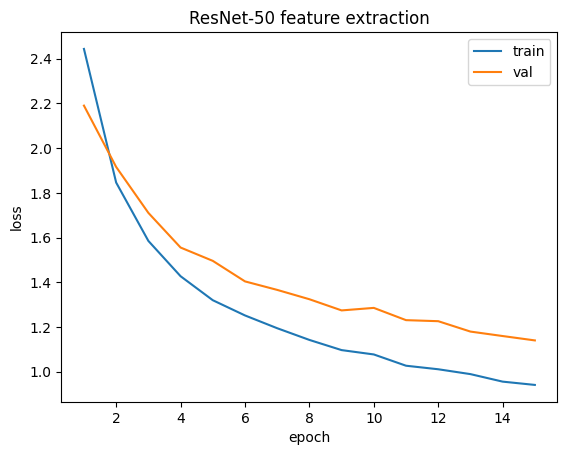

ResNet-50 feature extraction: val loss thấp nhất ở epoch 15


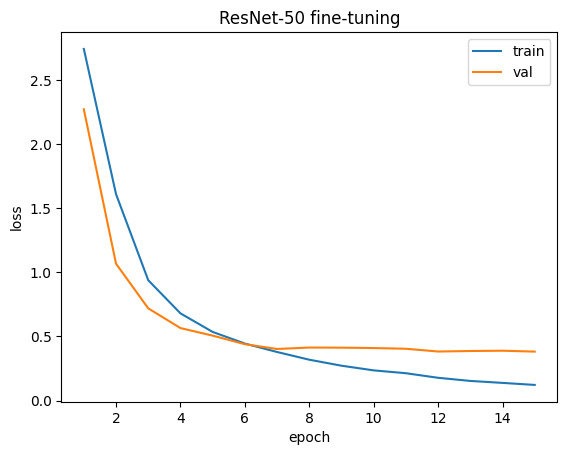

ResNet-50 fine-tuning: val loss thấp nhất ở epoch 15


,Mô hình,Resize,Tham số,Giây/epoch,Accuracy,Precision (macro),Recall (macro),F1 (macro)
0,ResNet-50 feature extraction,224x224,"23,551,061",1009.6,0.6173,0.6419,0.6221,0.6217
1,ResNet-50 fine-tuning,224x224,"23,551,061",2858.2,0.8622,0.8614,0.8665,0.8619


,lớp,F1 feature extraction,F1 fine-tuning
0,banh-can,0.6225,0.8671
1,banh-hoi,0.5840,0.8772
2,banh-mi-chao,0.6848,0.8993
3,banh-tet,0.6690,0.8952
4,banh-trang-tron,0.6418,0.8844
5,banh-u,0.6932,0.8865
6,banh-uot,0.4710,0.8073
7,bap-nuong,0.8175,0.9625
8,bo-kho,0.5226,0.8063
9,bo-la-lot,0.6627,0.9191


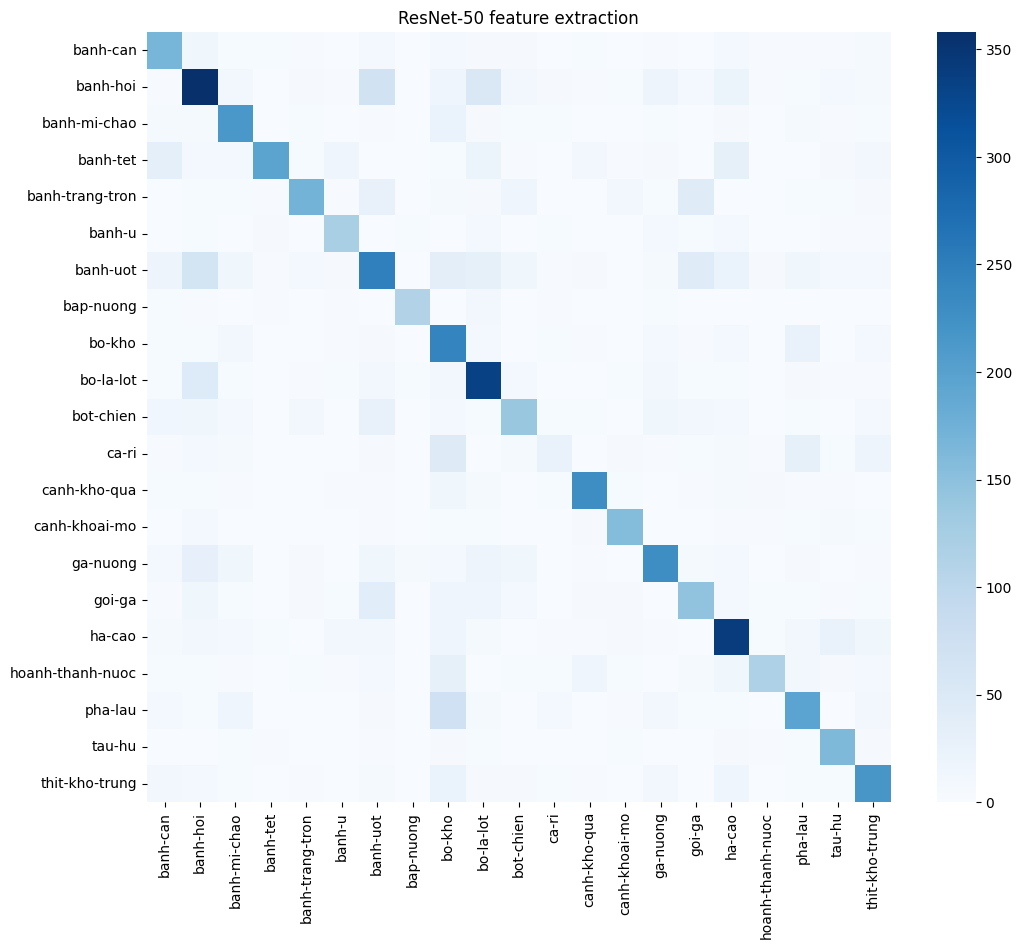

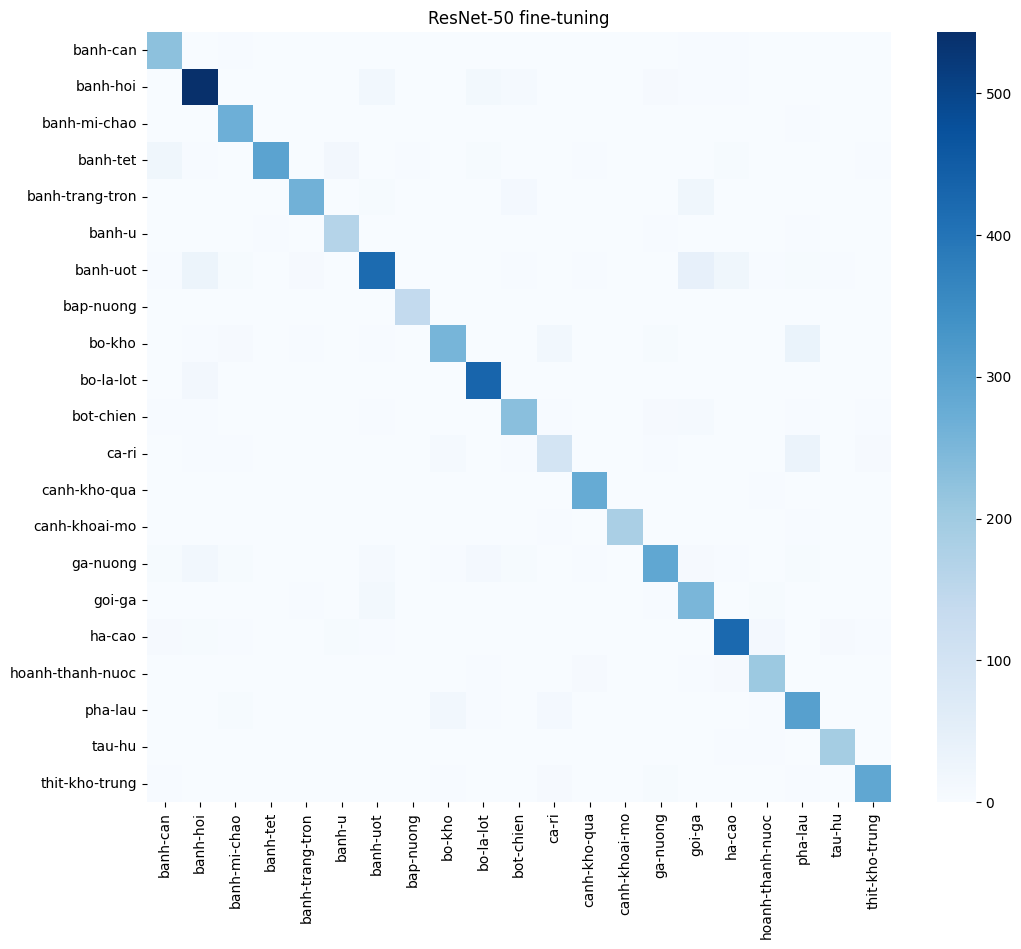

In [19]:
def best_epoch(res):
    return min(res["history"], key=lambda h: h[2])[0]

def f1_per_class(res):
    return precision_recall_fscore_support(
        res["y_true"], res["y_pred"], average=None, zero_division=0)[2].round(4)

for r in (res_fe, res_ft):
    plot_loss(r)
    print(f"{r['name']}: val loss thấp nhất ở epoch {best_epoch(r)}")

df4 = pd.DataFrame([{
    "Mô hình": r["name"], "Resize": "224x224", "Tham số": f"{r['params']:,}",
    "Giây/epoch": round(r["sec_per_epoch"], 1),
    "Accuracy": round(r["acc"], 4), "Precision (macro)": round(r["precision"], 4),
    "Recall (macro)": round(r["recall"], 4), "F1 (macro)": round(r["f1"], 4),
} for r in (res_fe, res_ft)])
display(df4)

display(pd.DataFrame({"lớp": CLASSES,
                      "F1 feature extraction": f1_per_class(res_fe),
                      "F1 fine-tuning": f1_per_class(res_ft)}))

report(res_fe, CLASSES)
report(res_ft, CLASSES)

**Nhận xét:**
- Đường loss: Feature extraction (chỉ train classifier) có train và val loss giảm đều, sát nhau (val loss 2.19 -> 1.14), chưa hội tụ hẳn nên gần như không overfitting. Fine-tuning giảm rất nhanh, val loss đi ngang từ khoảng epoch 7 trong khi train loss vẫn giảm, nên có overfitting nhẹ nhưng val loss không tăng.
- 4 độ đo: Fine-tuning vượt xa feature extraction (macro-F1 0.8619 so với 0.6217, accuracy 0.8622 so với 0.6173), đổi lại chậm hơn khoảng 2.8 lần (2858.2 so với 1009.6 giây/epoch). Cả hai đều vượt ResNet-18 huấn luyện từ đầu (macro-F1 0.4980), cho thấy pretrained rất hữu ích khi dữ liệu ít.
- F1 từng lớp: Fine-tuning cao hơn ở cả 21/21 lớp, tăng mạnh nhất ở ca-ri, banh-uot, bot-chien. bap-nuong từng rất khó với các mô hình huấn luyện từ đầu nhưng là lớp dễ nhất ở đây (0.96). ca-ri vẫn khó nhất (0.61).
- Confusion matrix: Fine-tuning có đường chéo đậm và gần như hết nhầm lẫn, cặp banh-hoi và banh-uot (nhầm nhiều ở Bài 1 đến 3) chỉ còn nhầm nhẹ. Feature extraction còn nhiều ô nhầm, nhất là ca-ri bị đoán thành bo-kho, pha-lau.

=> Kết luận: Với dữ liệu ít, backbone pretrained tốt hơn nhiều so với huấn luyện từ đầu. Fine-tuning cho kết quả tốt nhất (macro-F1 khoảng 0.86) nhưng tốn thời gian hơn feature extraction.